<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab3/lab3_1_text_visualization_classical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3.1 – Text visualization and classical representations

**Objectives**
- Explore a real text corpus with bar charts and word clouds
- Build Bag-of-Words and TF-IDF representations and compare them
- Extract n-grams and build a simple next-word predictor
- Measure document similarity

**Dataset:** [20 Newsgroups](https://huggingface.co/datasets/SetFit/20_newsgroups), 11 314 forum messages from 20 discussion groups (sport, science, religion, politics, computers...). Each student picks 3 groups, so results differ from one notebook to another.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**. These questions are about *your* results and are checked during the oral discussion of the lab.
3. When everything runs, follow the *Submission* section at the end.

## Setup

In [1]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
!pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [2]:
import os, re, string, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Setup complete")

Setup complete


---
# Part A – Load and explore the dataset

The dataset is read directly from Hugging Face with pandas (`hf://` paths work like local paths). A local copy shipped with the lab is used if the download fails.

In [3]:
def local_file(name, lab="lab3"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
    print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))

df = df.dropna(subset=["text"]).reset_index(drop=True)
print(f"Shape: {df.shape}, columns: {df.columns.tolist()}")
df["label_text"].value_counts()

Loaded from Hugging Face
Shape: (11314, 3), columns: ['text', 'label', 'label_text']


,count
label_text,
rec.sport.hockey,600
soc.religion.christian,599
rec.motorcycles,598
rec.sport.baseball,597
sci.crypt,595
sci.med,594
rec.autos,594
sci.space,593
comp.windows.x,593


In [4]:
print(f"Label: {df.iloc[0]['label_text']}")
print(df.iloc[0]["text"][:500])

Label: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


### Exercise A.1 – Choose your categories

Pick **exactly 3 categories** from the list printed above. The choice is yours; every result below depends on it.

In [5]:
print(sorted(df["label_text"].unique()))

my_categories = ["talk.politics.misc", "sci.space", "talk.politics.mideast"]  # YOUR CODE HERE: 3 category names copied from the list above

assert len(set(my_categories)) == 3 and all(c in df["label_text"].unique() for c in my_categories), "Pick 3 different valid categories"

df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)
print(f"Selected categories: {my_categories}")
print(f"Filtered dataset: {len(df_filtered)} documents")
df_filtered["label_text"].value_counts()

['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']
Selected categories: ['talk.politics.misc', 'sci.space', 'talk.politics.mideast']
Filtered dataset: 1622 documents


,count
label_text,
sci.space,593
talk.politics.mideast,564
talk.politics.misc,465


### Question A.2 (written)

Why these 3 categories? Are they related or very different? What vocabulary differences do you expect? (3 sentences minimum)

<!-- ANSWER lab3.1-A2 -->
I chose these three, because I wanted to compare different topics and also have two that are related. Sci.space is very different from the two political categories, while talk.politics.mideast and talk.politics.misc both discuss politics but probably focus on different subjects. I expect sci.space to contain words like "NASA" and "planet", while talk.politics.mideast may include "Israel", "Palestine", and "conflict". Talk.politics.misc has probably  more general political vocabulary like "government" and "election".
<!-- END ANSWER -->

---
# Part B – Preprocessing

The basic cleaning function below reuses what was done in Labs 1 and 2.

In [6]:
def preprocess_basic(text):
    """Lowercase; remove e-mails, URLs, numbers and punctuation; normalize whitespace."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(text.split())

sample = "Hello! Check this: http://example.com. Email me at test@email.com. Price: $100."
print(preprocess_basic(sample))

hello check this email me at price


### Exercise B.1 – Advanced preprocessing

Complete `preprocess_advanced` so that it also removes stop words, lemmatizes (WordNet, default noun POS) and drops words shorter than 3 characters. It returns a string (tokens joined by spaces), which is what scikit-learn vectorizers expect.

In [8]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_advanced(text):
    """Basic cleaning + stop word removal + lemmatization + minimum length 3. Returns a string."""
    # YOUR CODE HERE
    # 1. preprocess_basic
    text = preprocess_basic(text)
    # 2. tokenize
    tokens = word_tokenize(text)
    # 3. remove stop words
    tokens = [word for word in tokens if word not in stop_words]
    # 4. lemmatize
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    # 5. keep words with at least 3 characters
    tokens = [word for word in tokens if len(word) >= 3]
    # 6. join back into a string
    return " ".join(tokens)
    pass

sample = "The cats are running quickly towards the beautiful gardens. Email: test@mail.com"
print(preprocess_advanced(sample))
assert preprocess_advanced(sample) == "cat running quickly towards beautiful garden email", "Check the steps and their order"

cat running quickly towards beautiful garden email


In [ ]:
df_filtered["text_clean"] = df_filtered["text"].apply(preprocess_advanced)
print(df_filtered.iloc[0]["text_clean"][:300])

---
# Part C – Visualization

## C.1 Most frequent words per category

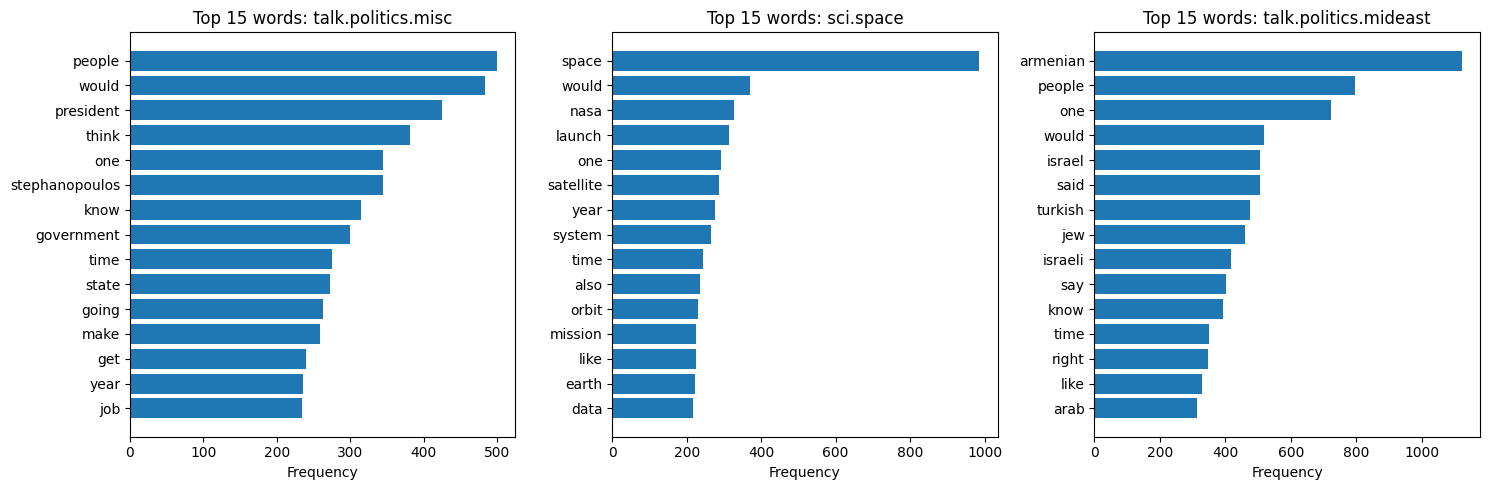

In [13]:
df_filtered["text_clean"] = df_filtered["text"].apply(preprocess_advanced)

def get_top_words(texts, n=15):
    """n most common words in a list of cleaned texts."""
    return Counter(" ".join(texts).split()).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, category in zip(axes, my_categories):
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    words, counts = zip(*get_top_words(texts, 15))
    ax.barh(words, counts)
    ax.invert_yaxis()
    ax.set_title(f"Top 15 words: {category}")
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

### Question C.1 (written)

1. Which words are specific to each category? (at least 2 per category)
2. Which words are shared by the 3 categories, and why?
3. Could you guess the topic of each category from its top words only?

<!-- ANSWER lab3.1-C1 -->
**1. Which words are specific to each category?**
- talk.politics.misc: "president", "government", "state" -> related to general politics.
- sci.space: "NASA", "satellite", "orbit", "launch" -> related to space.
- talk.politics.mideast: "Armenian", "Israel", "Turkish", "Arab" -> related to Middle East politics and conflicts.

**2. Which words are shared by the 3 categories, and why?**
Words like "would", "one", and "time" appear in all three categories. These are common English words used in discussions regardless of the topic. They do not provide much information about the specific category.

**3. Could you guess the topic of each category from its top words only?**
Yes, the topics are relatively easy to identify. Words like "space" and "nasa"  indicate space, while "president" and "people" suggest general politics. Words like "Armenian", "people", and "Israel" suggest political discussions about the Middle East.
<!-- END ANSWER -->

## C.2 Word clouds

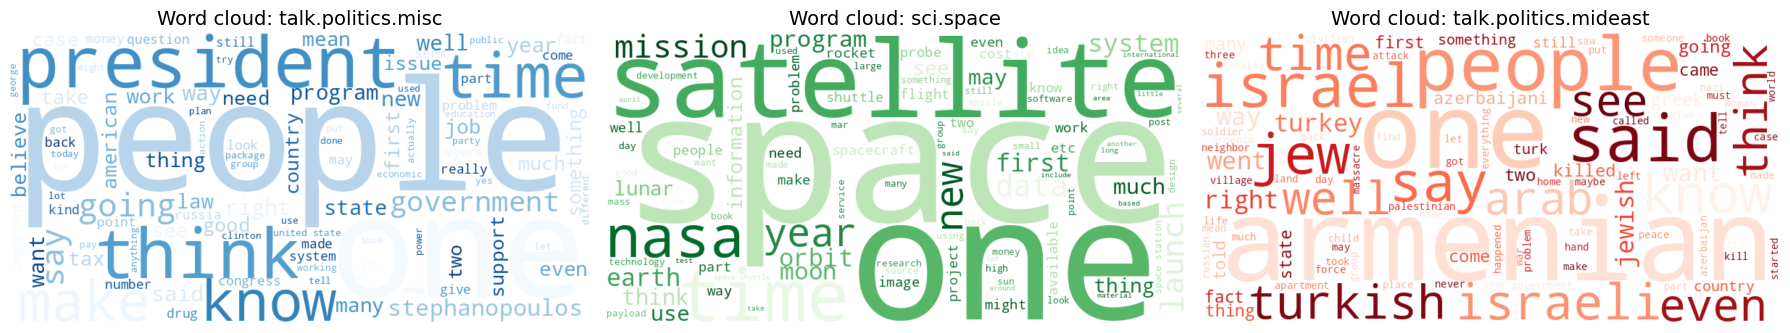

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, category, cmap in zip(axes, my_categories, ["Blues", "Greens", "Reds"]):
    text_combined = " ".join(df_filtered.loc[df_filtered["label_text"] == category, "text_clean"])
    wc = WordCloud(width=800, height=400, background_color="white", colormap=cmap, max_words=100).generate(text_combined)
    ax.imshow(wc.to_image(), interpolation="bilinear")
    ax.set_title(f"Word cloud: {category}", fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Exercise C.2 – Word cloud with a custom shape

`WordCloud` accepts a `mask` (a 2-D array where 255 = area to fill, 0 = area to leave blank). The cell below builds a circular mask; any black-and-white silhouette image opened with `PIL.Image` and converted to an array works as well.

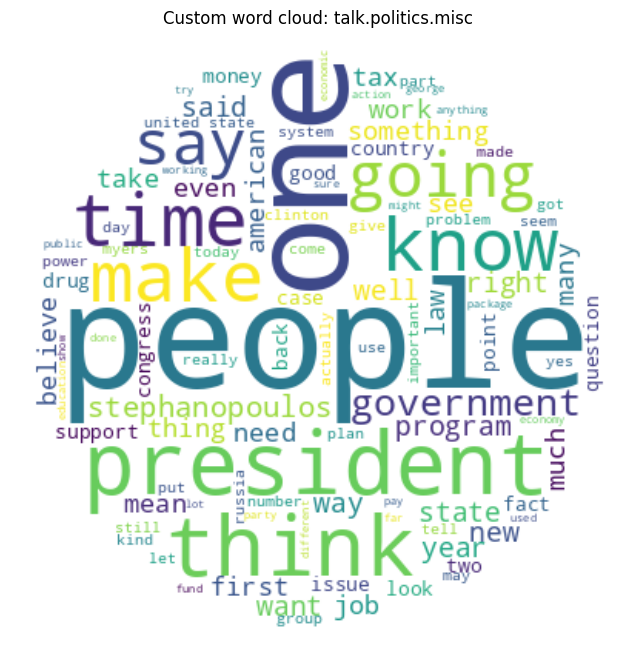

In [19]:
from PIL import Image

def circle_mask(size=400):
    y, x = np.ogrid[:size, :size]
    center, r = size // 2, size // 2 - 10
    mask = np.full((size, size), 255, dtype=np.uint8)   # 255 = masked out
    mask[(x - center) ** 2 + (y - center) ** 2 <= r ** 2] = 0   # 0 = draw here
    return mask

mask = circle_mask()
# To use your own image instead:  mask = np.array(Image.open("my_shape.png").convert("L"))

selected_category = "talk.politics.misc"  # YOUR CODE HERE: one of your categories
texts = df_filtered.loc[df_filtered["label_text"] == selected_category, "text_clean"]
wordcloud_masked = WordCloud(width=800, height=800, background_color="white", mask=mask, max_words=100, colormap="viridis").generate(" ".join(texts))
# YOUR CODE HERE: WordCloud(..., mask=mask, ...).generate(...)

plt.figure(figsize=(8, 8))
plt.imshow(wordcloud_masked.to_image(), interpolation="bilinear")
plt.title(f"Custom word cloud: {selected_category}")
plt.axis("off")
plt.show()

---
# Part D – Bag of Words

In [20]:
sample_docs = ["I love machine learning", "Machine learning is great", "I love deep learning too"]

bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(sample_docs)

print("Vocabulary:", bow_vectorizer.get_feature_names_out())
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=bow_vectorizer.get_feature_names_out())
bow_df

Vocabulary: ['deep' 'great' 'is' 'learning' 'love' 'machine' 'too']


,deep,great,is,learning,love,machine,too
0,0,0,0,1,1,1,0
1,0,1,1,1,0,1,0
2,1,0,0,1,1,0,1


### Exercise D.1 – Bag of Words of your corpus

In [22]:
# Build the BoW matrix of df_filtered["text_clean"] with max_features=1000, min_df=5, max_df=0.95
bow_vectorizer_full = CountVectorizer(max_features=1000, min_df=5, max_df=0.95)  # YOUR CODE HERE
bow_matrix_full = bow_vectorizer_full.fit_transform(df_filtered["text_clean"])      # YOUR CODE HERE

print(f"BoW matrix shape: {bow_matrix_full.shape}")
print(f"Sparsity: {100 * (1 - bow_matrix_full.nnz / np.prod(bow_matrix_full.shape)):.1f}% of zeros")
print(f"First 20 words: {bow_vectorizer_full.get_feature_names_out()[:20]}")
assert bow_matrix_full.shape == (len(df_filtered), 1000), "Check the vectorizer parameters"

BoW matrix shape: (1622, 1000)
Sparsity: 95.7% of zeros
First 20 words: ['able' 'accept' 'access' 'according' 'account' 'across' 'act' 'action'
 'activity' 'actually' 'adam' 'add' 'addition' 'address' 'adl'
 'administration' 'affair' 'afraid' 'age' 'agency']


### Exercise D.2 – Document similarity

In [27]:
# 1. Compute the cosine similarity matrix between all documents (BoW vectors)
# 2. Find the most similar pair of distinct documents (ignore the diagonal)
similarity_matrix = cosine_similarity(bow_matrix_full)   # YOUR CODE HERE
np.fill_diagonal(similarity_matrix, -1)
most_similar_idx = np.unravel_index(
    np.argmax(similarity_matrix), similarity_matrix.shape
    ) # YOUR CODE HERE: (i, j) tuple, i != j
most_similar_score = similarity_matrix[most_similar_idx]  # YOUR CODE HERE

print(f"Similarity matrix shape: {similarity_matrix.shape}")
print(f"Most similar documents: {most_similar_idx}, score = {most_similar_score:.3f}")
assert similarity_matrix.shape == (len(df_filtered), len(df_filtered)) and most_similar_idx[0] != most_similar_idx[1]

for k, idx in enumerate(most_similar_idx, 1):
    print(f"\nDocument {k} ({df_filtered.iloc[idx]['label_text']}):")
    print(df_filtered.iloc[idx]["text"][:300])

Similarity matrix shape: (1622, 1622)
Most similar documents: (np.int64(659), np.int64(689)), score = 1.000

Document 1 (sci.space):
Can someone please remind me who said a well known quotation? 

He was sitting atop a rocket awaiting liftoff and afterwards, in answer to
the question what he had been thinking about, said (approximately) "half a
million components, each has to work perfectly, each supplied by the lowest
bidder....

Document 2 (sci.space):
Can someone please remind me who said a well known quotation? 

He was sitting atop a rocket awaiting liftoff and afterwards, in answer to
the question what he had been thinking about, said (approximately) "half a
million components, each has to work perfectly, each supplied by the lowest
bidder....


### Question D.3 (written)

1. Are the two most similar documents from the same category?
2. Reading them, what makes them similar?
3. Is BoW cosine similarity meaningful here? Why?

<!-- ANSWER lab3.1-D3 -->
**1. Are the two most similar documents from the same category?**
Yes, both documents belong to sci.space category and have a similarity score of 1.000.

**2. Reading them, what makes them similar?**
The documents appear to be identical. They contain the same text about a quotation from someone sitting on a rocket before liftoff.

**3. Is BoW cosine similarity meaningful here? Why?**
Yes, because it correctly identifies the two documents as highly similar based on their word frequencies. However, BoW does not understand the meaning or context of words. In this case, the score of 1.000 is unsurprising because the documents appear to be duplicates.
<!-- END ANSWER -->

---
# Part E – TF-IDF

In [28]:
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(sample_docs)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out()).round(3)
tfidf_df

,deep,great,is,learning,love,machine,too
0,0.000,0.000,0.000,0.481,0.620,0.620,0.000
1,0.000,0.584,0.584,0.345,0.000,0.445,0.000
2,0.584,0.000,0.000,0.345,0.445,0.000,0.584


In [29]:
print("Scores of the word 'learning' (present in every document):")
print("  BoW:   ", bow_df["learning"].tolist())
print("  TF-IDF:", tfidf_df["learning"].tolist(), "-> lower weight for a word shared by all documents")

Scores of the word 'learning' (present in every document):
  BoW:    [1, 1, 1]
  TF-IDF: [0.481, 0.345, 0.345] -> lower weight for a word shared by all documents


### Exercise E.1 – TF-IDF of your corpus and top words per category

In [31]:
tfidf_vectorizer_full = TfidfVectorizer(max_features=1000, min_df=5, max_df=0.95)  # YOUR CODE HERE (same parameters as the BoW)
tfidf_matrix_full = tfidf_vectorizer_full.fit_transform(df_filtered["text_clean"])    # YOUR CODE HERE
print(f"TF-IDF matrix shape: {tfidf_matrix_full.shape}")

def get_top_tfidf_words(category, n=10):
    """Words with the highest mean TF-IDF over the documents of a category."""
    # YOUR CODE HERE
    # 1. indices of the documents of this category
    indices = np.where(df_filtered["label_text"] == category)[0]
    # 2. their TF-IDF rows
    category_matrix = tfidf_matrix_full[indices]
    # 3. mean score of each word over these rows
    mean_scores = np.asarray(category_matrix.mean(axis=0)).ravel()
    # 4. the n words with the highest mean
    top_indices = np.argsort(mean_scores)[-n:][::-1]
    words = tfidf_vectorizer_full.get_feature_names_out()
    return [(words[i], mean_scores[i]) for i in top_indices]
    pass

for category in my_categories:
    print(f"\nTop TF-IDF words for '{category}':")
    print(get_top_tfidf_words(category, 10))
assert len(get_top_tfidf_words(my_categories[0], 10)) == 10

TF-IDF matrix shape: (1622, 1000)

Top TF-IDF words for 'talk.politics.misc':
[('people', np.float64(0.042477862067826694)), ('would', np.float64(0.03630491768799772)), ('tax', np.float64(0.032431056794238536)), ('government', np.float64(0.03017878425036146)), ('one', np.float64(0.029152749762336866)), ('state', np.float64(0.02720932409901484)), ('law', np.float64(0.026991463386403538)), ('think', np.float64(0.0267557902712822)), ('homosexual', np.float64(0.026643968142085098)), ('make', np.float64(0.02577988921153889))]

Top TF-IDF words for 'sci.space':
[('space', np.float64(0.073020155426393)), ('would', np.float64(0.03892610522920654)), ('nasa', np.float64(0.02909753745645822)), ('like', np.float64(0.028442635380340427)), ('one', np.float64(0.027925394646888826)), ('orbit', np.float64(0.027060276750363255)), ('launch', np.float64(0.026474099703022204)), ('moon', np.float64(0.023841794051598246)), ('get', np.float64(0.023630112859617265)), ('think', np.float64(0.021914973907553596))

### Question E.2 (written)

Compare with the word counts of Part C:
1. Which words appear in the TF-IDF top 10 but not in the count top 15?
2. Which words appear in the count top 15 but not in the TF-IDF top 10?
3. Which representation captures the *topic* of each category better? Why?

<!-- ANSWER lab3.1-E2 -->
**1. Which words appear in the TF-IDF top 10 but not in the count top 15?**
talk.politics.misc: tax, law, homosexual
sci.space: moon, get, think
talk.politics.mideast: palestinian

**2. Which words appear in the count top 15 but not in the TF-IDF top 10?**
talk.politics.misc: president, stephanopoulos, know, time, going, get, year, job
sci.space: one, year, system, time, also, mission, earth, data
talk.politics.mideast: said, say, know, time, right, like

**3. Which representation captures the topic of each category better? Why?**
TF-IDF generally captures the topic better because it gives more importance to distinctive words and reduces the influence of common words. Word counts mainly show which words appear most frequently, even when they are not particularly informative about the topic.

<!-- END ANSWER -->

---
# Part F – N-grams and next-word prediction

In [32]:
from nltk import ngrams

tokens = "I love natural language processing and machine learning".split()
print("Bigrams: ", list(ngrams(tokens, 2)))
print("Trigrams:", list(ngrams(tokens, 3)))

# CountVectorizer can also build n-gram features
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2))
bigram_vectorizer.fit(["I love machine learning", "Machine learning is great"])
print("Bigram features:", bigram_vectorizer.get_feature_names_out())

Bigrams:  [('I', 'love'), ('love', 'natural'), ('natural', 'language'), ('language', 'processing'), ('processing', 'and'), ('and', 'machine'), ('machine', 'learning')]
Trigrams: [('I', 'love', 'natural'), ('love', 'natural', 'language'), ('natural', 'language', 'processing'), ('language', 'processing', 'and'), ('processing', 'and', 'machine'), ('and', 'machine', 'learning')]
Bigram features: ['is great' 'learning is' 'love machine' 'machine learning']


### Exercise F.1 – Most frequent bigrams per category

In [33]:
def top_bigrams(texts, n=15):
    """(bigram, count) list of the n most frequent bigrams in the texts."""
    # YOUR CODE HERE
    # 1. CountVectorizer(ngram_range=(2, 2), min_df=3) fitted on the texts
    # 2. sum the columns to count each bigram
    # 3. return the n most frequent (bigram, count)

    vectorizer = CountVectorizer(ngram_range=(2, 2), min_df=3)
    matrix = vectorizer.fit_transform(texts)

    counts = np.asarray(matrix.sum(axis=0)).ravel()

    top_indices = np.argsort(counts)[::-1][:n]
    bigrams = vectorizer.get_feature_names_out()

    return [(bigrams[i], int(counts[i])) for i in top_indices]
    pass

for category in my_categories:
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    print(f"\nTop bigrams for '{category}':")
    for bigram, count in top_bigrams(texts, 15):
        print(f"  {bigram}: {count}")
assert len(top_bigrams(df_filtered["text_clean"], 5)) == 5


Top bigrams for 'talk.politics.misc':
  united state: 83
  health care: 62
  white house: 56
  administration official: 53
  young people: 48
  stephanopoulos think: 45
  stephanopoulos know: 38
  working group: 36
  los angeles: 35
  stimulus package: 34
  new york: 32
  summer job: 32
  stephanopoulos well: 31
  task force: 28
  senator dole: 25

Top bigrams for 'sci.space':
  space station: 69
  space shuttle: 66
  sci space: 58
  anonymous ftp: 38
  remote sensing: 32
  commercial space: 32
  gamma ray: 28
  launch vehicle: 27
  national space: 26
  sci astro: 25
  air force: 24
  nasa gov: 24
  nasa ames: 24
  space technology: 23
  pub space: 21

Top bigrams for 'talk.politics.mideast':
  serdar argic: 94
  human right: 91
  new york: 51
  woman child: 50
  armenian government: 48
  world war: 45
  year old: 45
  soviet armenia: 41
  muslim people: 40
  genocide million: 40
  soviet armenian: 39
  ottoman empire: 39
  million muslim: 39
  turk kurd: 38
  united state: 38


### Exercise F.2 – A bigram next-word predictor

The probability of a word given the previous one is estimated by counting: P(w2 | w1) = count(w1, w2) / count(w1).

In [37]:
class BigramPredictor:
    def __init__(self):
        self.bigram_counts = {}   # {word1: Counter({word2: count, ...})}
        self.unigram_counts = Counter()

    def train(self, texts):
        """Count unigrams and bigrams over a list of texts (strings)."""
        # YOUR CODE HERE
        for text in texts:
            words = text.split()

            # Count individual words
            self.unigram_counts.update(words)

            # Count consecutive word pairs
            for word1, word2 in zip(words[:-1], words[1:]):
                if word1 not in self.bigram_counts:
                    self.bigram_counts[word1] = Counter()

                self.bigram_counts[word1][word2] += 1
        pass

    def predict_next(self, word, top_n=5):
        """Return the top_n (next_word, probability) pairs for a word."""
        # YOUR CODE HERE

        if word not in self.bigram_counts:
            return []

        next_words = self.bigram_counts[word]
        total = sum(next_words.values())

        return [(w, count / total) for w, count in next_words.most_common(top_n)]

# Sanity check on a tiny corpus
toy = BigramPredictor()
toy.train(["the cat sat on the mat", "the cat ate the fish"])
print(toy.predict_next("the"))
assert toy.predict_next("the")[0] == ("cat", 0.5), "P(cat | the) should be 2/4"
assert toy.predict_next("cat") == [("sat", 0.5), ("ate", 0.5)] or toy.predict_next("cat") == [("ate", 0.5), ("sat", 0.5)]

predictor = BigramPredictor()
predictor.train(df_filtered["text_clean"])

[('cat', 0.5), ('mat', 0.25), ('fish', 0.25)]


In [38]:
# Choose 5 words related to YOUR categories and look at the predictions
test_words = ["space", "nasa", "government", "people", "israel"]  # YOUR CODE HERE

for word in test_words:
    print(f"\n'{word}' ->")
    for next_word, prob in predictor.predict_next(word.lower(), top_n=5):
        print(f"  {next_word}: {prob:.3f}")


'space' ->
  station: 0.069
  shuttle: 0.066
  technology: 0.023
  program: 0.022
  science: 0.019

'nasa' ->
  ames: 0.073
  gov: 0.073
  center: 0.036
  budget: 0.021
  jsc: 0.018

'government' ->
  agency: 0.021
  would: 0.015
  regulation: 0.015
  greece: 0.013
  policy: 0.011

'people' ->
  would: 0.015
  like: 0.015
  ball: 0.010
  want: 0.010
  know: 0.009

'israel' ->
  would: 0.024
  withdraw: 0.020
  border: 0.010
  must: 0.010
  palestine: 0.010


### Question F.3 (written)

1. Give 2 sensible predictions and 2 poor ones.
2. What are the limits of a bigram model?
3. How could the predictor be improved? (3 ideas)

<!-- ANSWER lab3.1-F3 -->
**1. Give 2 sensible predictions and 2 poor ones.**
Sensible: "space → station" (0.069) and "government → agency" (0.021), because both combinations make sense.
Poor: "people → ball" (0.010) and "government → greece" (0.013), because these combinations are less natural without additional context.

**2. What are the limits of a bigram model?**
A bigram model only considers the previous word and does not understand the full sentence or its meaning. This can lead to predictions that do not make sense in context.

**3. How could the predictor be improved? (3 ideas)**
Use trigrams: Consider the previous two words instead of only one.
Use more training data: Learn from more examples to improve accuracy.
Use advanced models: Transformers can consider longer contexts and produce more meaningful predictions.
<!-- END ANSWER -->

---
# Part G – Document similarity heatmap

TF-IDF cosine similarity between 30 documents (10 per category).

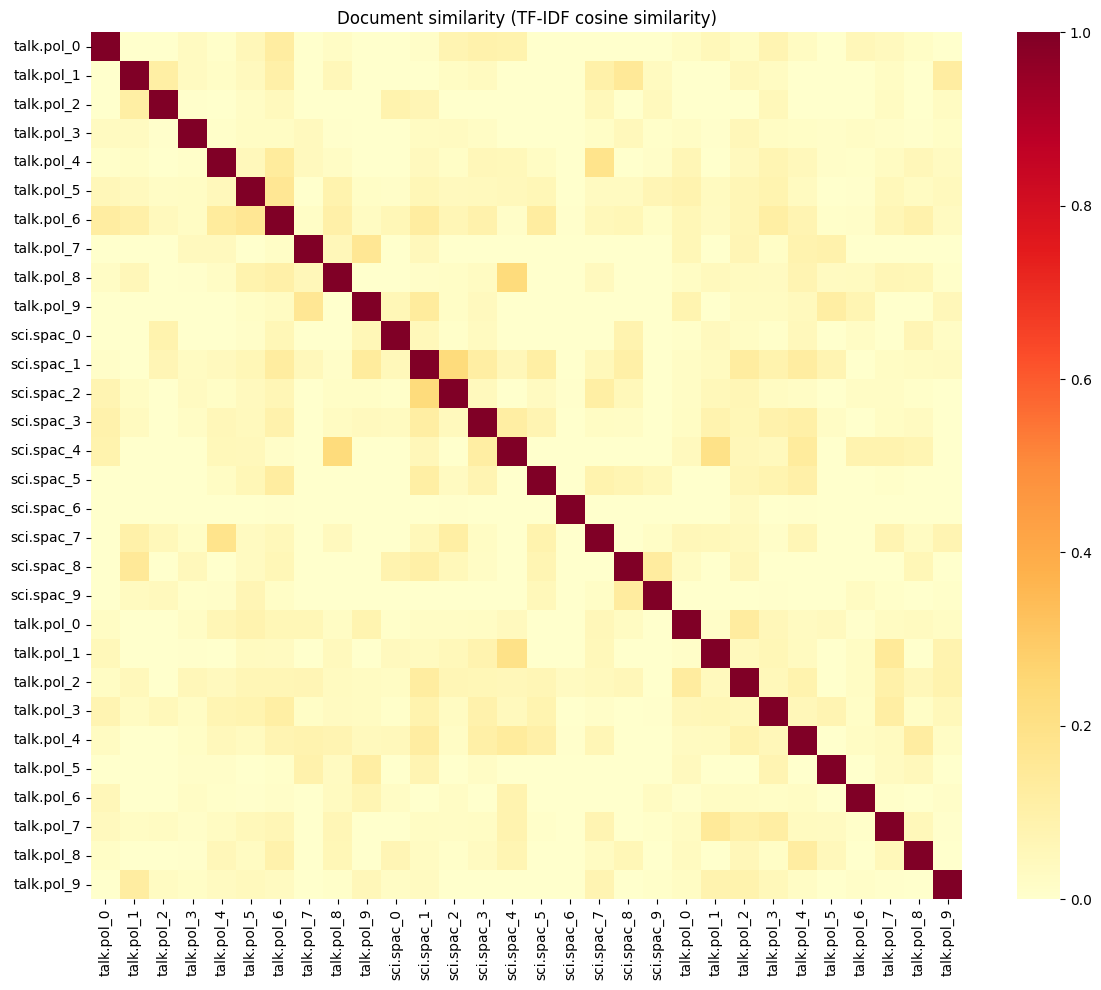

In [39]:
df_sampled = pd.concat([df_filtered[df_filtered["label_text"] == c].sample(n=10, random_state=42) for c in my_categories]).reset_index(drop=True)
tfidf_sampled = TfidfVectorizer(max_features=500).fit_transform(df_sampled["text_clean"])
similarity_sampled = cosine_similarity(tfidf_sampled)

labels = [f"{cat[:8]}_{i % 10}" for i, cat in enumerate(df_sampled["label_text"])]
plt.figure(figsize=(12, 10))
sns.heatmap(similarity_sampled, xticklabels=labels, yticklabels=labels, cmap="YlOrRd")
plt.title("Document similarity (TF-IDF cosine similarity)")
plt.tight_layout()
plt.show()

### Question G.1 (written)

1. Do documents of the same category form brighter blocks along the diagonal?
2. Which pair of categories is the most similar? The least similar?
3. Any surprising similarity between documents of different categories? What could explain it?

<!-- ANSWER lab3.1-G1 -->
**1. Do documents of the same category form brighter blocks along the diagonal?**
Not clearly. There are some brighter areas within the same categories, especially in sci.space, but most similarities are relatively low. This suggests that documents within the same category can discuss different subjects.

**2. Which pair of categories is the most similar? The least similar?**
Most similar: talk.politics.misc and talk.politics.mideast, because both discuss political topics and share vocabulary.
Least similar: sci.space and talk.politics.mideast, because they focus on very different subjects.
These are general interpretations; the heatmap does not show a strong enough pattern to confirm the exact ranking.

**3. Any surprising similarity between documents of different categories? What could explain it?**
Yes, some documents from different categories show some similarity. This could be because they share common words or discuss overlapping subjects, such as government policies related to space exploration. TF-IDF measures shared vocabulary rather than fully understanding the meaning of the documents.
<!-- END ANSWER -->

---
## Summary

- Word counts and word clouds give a first picture of a corpus, after cleaning.
- Bag of Words counts words; TF-IDF down-weights words shared by many documents.
- N-grams capture short sequences; a bigram model is the simplest language model.
- Cosine similarity on these vectors measures lexical overlap, not meaning. Lab 3.2 moves to embeddings.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.